# GAT on the entity graph (IEEE-CIS fraud)
**Pipeline:** the graph has only *entity* nodes (card1, addr1, P_emaildomain, R_emaildomain, DeviceInfo, DeviceType; 14,239 nodes). A payment is not a node: each payment row stores the 6 entity node ids it touches. So the GAT learns an embedding for every entity node, and a payment is classified from the concatenation of its 6 entity embeddings.

**Sections:** setup -> data -> model (functions) -> GAT on the real graph -> controls on the 3 shuffled graphs (seeds 1, 2, 42) -> comparison table.
The shuffled graphs are the control: same payments, but the entity-entity links were rebuilt after permuting each entity column. If the real graph beats them, the graph structure carries signal.

## 0. Setup

In [7]:
!pip install -q torch_geometric

In [8]:
import json, random, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GATConv
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, precision_score, recall_score, f1_score)
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# CHANGE THIS to the Drive folder that holds the graph files
DATA_DIR = '/content/drive/MyDrive/fraud_project/data/graph_files'

PATHS = {
    'real':    f'{DATA_DIR}/graph_edges.npy',
    'shuf1':   f'{DATA_DIR}/graph_shuf_seed1_edges.npy',
    'shuf2':   f'{DATA_DIR}/graph_shuf_seed2_edges.npy',
    'shuf42':  f'{DATA_DIR}/graph_shuf_seed42_edges.npy',
}
SEED = 42
RESULTS = {}   # filled by each model's Results cell

In [11]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

## 1. Data

In [12]:
info = json.load(open(f'{DATA_DIR}/graph_info.json'))
ENT_COLS = info['entity_columns']
NUM_NODES = info['num_nodes']
node_type = torch.from_numpy(np.load(f'{DATA_DIR}/node_type.npy')).long()
N_TYPES = int(node_type.max()) + 1
print(ENT_COLS, NUM_NODES, N_TYPES)
assert node_type.shape[0] == NUM_NODES

['card1', 'addr1', 'P_emaildomain', 'R_emaildomain', 'DeviceInfo', 'DeviceType'] 14239 6


In [13]:
train_df = pd.read_parquet(f'{DATA_DIR}/payment_nodes_train.parquet')
val_df   = pd.read_parquet(f'{DATA_DIR}/payment_nodes_val.parquet')
test_df  = pd.read_parquet(f'{DATA_DIR}/payment_nodes_test.parquet')

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, d.shape, 'fraud rate = %.4f' % d['isFraud'].mean())
train_df.head()

train (413378, 8) fraud rate = 0.0352
val (88581, 8) fraud rate = 0.0343
test (88581, 8) fraud rate = 0.0348


,TransactionID,isFraud,card1,addr1,P_emaildomain,R_emaildomain,DeviceInfo,DeviceType
0,2987000,0,0,12244,12623,12685,14233,14237
1,2987001,0,1,12245,12564,12685,14233,14237
2,2987002,0,2,12246,12565,12685,14233,14237
3,2987003,0,3,12247,12566,12685,14233,14237
4,2987004,0,4,12248,12564,12685,12687,14235


In [14]:
def to_tensors(d):
    ent = torch.from_numpy(d[ENT_COLS].values.astype(np.int64))
    y   = torch.from_numpy(d['isFraud'].values.astype(np.float32))
    return ent.to(device), y.to(device)

ent_train, y_train = to_tensors(train_df)
ent_val,   y_val   = to_tensors(val_df)
ent_test,  y_test  = to_tensors(test_df)

# sanity: every node id must exist in the graph
for e in (ent_train, ent_val, ent_test):
    assert int(e.max()) < NUM_NODES and int(e.min()) >= 0

In [15]:
def load_edges(path):
    e = torch.from_numpy(np.load(path)).long()   # [2, E], both directions already present
    assert e.shape[0] == 2
    return e.to(device)

# class imbalance -> positive-class weight for BCE
pos_weight = torch.tensor([(1 - y_train.mean().item()) / y_train.mean().item()], device=device)
print('pos_weight = %.1f' % pos_weight.item())

pos_weight = 27.4


## 2. Model, Train (function), Validate (function)

In [16]:
class GAT(nn.Module):
    """Learnable node embedding + type embedding -> 2 GAT layers -> payment head on the 6 entity embeddings."""
    def __init__(self, num_nodes, node_type, n_types, n_entities=6,
                 emb_dim=64, hidden=64, heads=4, dropout=0.3, attn_dropout=0.2):
        super().__init__()
        self.node_emb = nn.Embedding(num_nodes, emb_dim)
        self.type_emb = nn.Embedding(n_types, emb_dim)
        self.register_buffer('node_type', node_type)
        self.conv1 = GATConv(emb_dim, hidden, heads=heads, dropout=attn_dropout)       # -> hidden*heads
        self.conv2 = GATConv(hidden * heads, hidden, heads=1, dropout=attn_dropout)    # -> hidden
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(
            nn.Linear(hidden * n_entities, 128), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(128, 1))

    def encode(self, edge_index):
        x = self.node_emb.weight + self.type_emb(self.node_type)
        x = self.drop(x)
        x = F.elu(self.conv1(x, edge_index))
        x = self.drop(x)
        return self.conv2(x, edge_index)                 # [num_nodes, hidden]

    def classify(self, h, ent):                          # ent: [B, 6] node ids
        return self.head(h[ent].flatten(1)).squeeze(-1)  # logits [B]

In [17]:
def train_epoch(model, edge_index, ent, y, optimizer, criterion, batch_size=16384):
    model.train()
    perm = torch.randperm(ent.shape[0], device=ent.device)
    total = 0.0
    for i in range(0, len(perm), batch_size):
        idx = perm[i:i + batch_size]
        h = model.encode(edge_index)                     # graph is small, re-encode each step
        loss = criterion(model.classify(h, ent[idx]), y[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(idx)
    return total / len(perm)

In [18]:
@torch.no_grad()
def validate(model, edge_index, ent, y, criterion, batch_size=65536):
    model.eval()
    h = model.encode(edge_index)
    logits = torch.cat([model.classify(h, ent[i:i + batch_size])
                        for i in range(0, ent.shape[0], batch_size)])
    loss = criterion(logits, y).item()
    probs = torch.sigmoid(logits).cpu().numpy()
    yy = y.cpu().numpy()
    return {'loss': loss,
            'auprc': average_precision_score(yy, probs),
            'auroc': roc_auc_score(yy, probs),
            'probs': probs}

In [19]:
def best_threshold(y_true, probs):
    p, r, t = precision_recall_curve(y_true, probs)
    f1 = 2 * p * r / (p + r + 1e-12)
    return float(t[np.argmax(f1[:-1])])

def test_report(y_true, probs, thr):
    pred = (probs >= thr).astype(int)
    return {'AUPRC': average_precision_score(y_true, probs),
            'AUROC': roc_auc_score(y_true, probs),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'Threshold': thr}

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
EPOCHS, PATIENCE, LR, WD = 60, 8, 1e-3, 1e-5

## GAT (real graph)

### GAT (real graph) - Setup

In [20]:
set_seed(SEED)
edge_index_real = load_edges(PATHS['real'])
print('edges:', edge_index_real.shape)
model_real = GAT(NUM_NODES, node_type.to(device), N_TYPES).to(device)
opt_real = torch.optim.AdamW(model_real.parameters(), lr=LR, weight_decay=WD)
print(sum(p.numel() for p in model_real.parameters()), 'parameters')

edges: torch.Size([2, 336236])
994817 parameters


### GAT (real graph) - Train

In [21]:
hist_real = []
best_real = {'auprc': -1, 'epoch': 0, 'state': None}
bad = 0
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model_real, edge_index_real, ent_train, y_train, opt_real, criterion)
    va = validate(model_real, edge_index_real, ent_val, y_val, criterion)
    hist_real.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': va['loss'],
                        'val_auprc': va['auprc'], 'val_auroc': va['auroc']})
    print(f"epoch {epoch:02d} | train {tr_loss:.4f} | val {va['loss']:.4f} | "
          f"AUPRC {va['auprc']:.4f} | AUROC {va['auroc']:.4f}")
    if va['auprc'] > best_real['auprc']:
        best_real = {'auprc': va['auprc'], 'epoch': epoch,
                      'state': {k: v.detach().clone() for k, v in model_real.state_dict().items()}}
        bad = 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop'); break

epoch 01 | train 1.2519 | val 1.2062 | AUPRC 0.0903 | AUROC 0.7205
epoch 02 | train 1.2054 | val 1.1695 | AUPRC 0.1002 | AUROC 0.7182
epoch 03 | train 1.1985 | val 1.1645 | AUPRC 0.1082 | AUROC 0.7222
epoch 04 | train 1.1899 | val 1.1608 | AUPRC 0.1126 | AUROC 0.7264
epoch 05 | train 1.1804 | val 1.1639 | AUPRC 0.1180 | AUROC 0.7275
epoch 06 | train 1.1768 | val 1.1535 | AUPRC 0.1199 | AUROC 0.7282
epoch 07 | train 1.1671 | val 1.1687 | AUPRC 0.1228 | AUROC 0.7279
epoch 08 | train 1.1616 | val 1.1910 | AUPRC 0.1210 | AUROC 0.7281
epoch 09 | train 1.1572 | val 1.1495 | AUPRC 0.1316 | AUROC 0.7310
epoch 10 | train 1.1434 | val 1.1513 | AUPRC 0.1331 | AUROC 0.7360
epoch 11 | train 1.1411 | val 1.1425 | AUPRC 0.1357 | AUROC 0.7362
epoch 12 | train 1.1363 | val 1.1376 | AUPRC 0.1372 | AUROC 0.7408
epoch 13 | train 1.1348 | val 1.1682 | AUPRC 0.1438 | AUROC 0.7384
epoch 14 | train 1.1293 | val 1.1378 | AUPRC 0.1385 | AUROC 0.7396
epoch 15 | train 1.1203 | val 1.1269 | AUPRC 0.1508 | AUROC 0.

### GAT (real graph) - Best Epoch

best epoch: 31 | val AUPRC: 0.1866


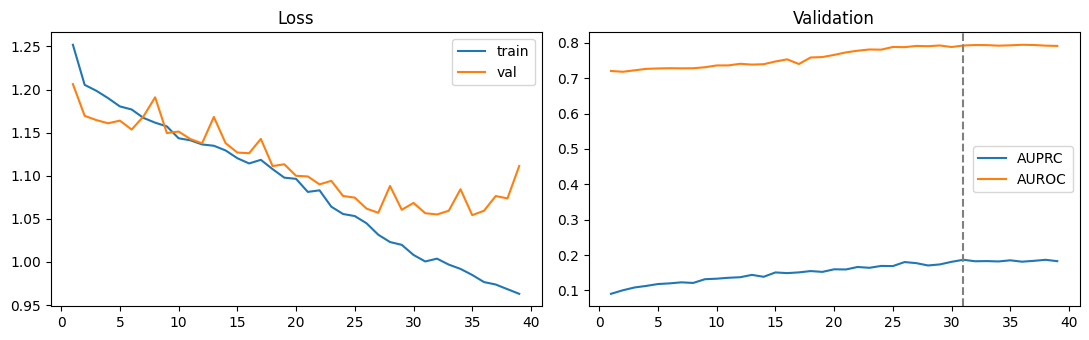

In [22]:
h_real = pd.DataFrame(hist_real)
print('best epoch:', best_real['epoch'], '| val AUPRC: %.4f' % best_real['auprc'])
model_real.load_state_dict(best_real['state'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_real.epoch, h_real.train_loss, label='train'); ax[0].plot(h_real.epoch, h_real.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h_real.epoch, h_real.val_auprc, label='AUPRC'); ax[1].plot(h_real.epoch, h_real.val_auroc, label='AUROC')
ax[1].axvline(best_real['epoch'], ls='--', c='gray'); ax[1].set_title('Validation'); ax[1].legend()
plt.tight_layout(); plt.show()

### GAT (real graph) - Results

In [23]:
va = validate(model_real, edge_index_real, ent_val, y_val, criterion)
thr = best_threshold(y_val.cpu().numpy(), va['probs'])      # threshold picked on validation only
te = validate(model_real, edge_index_real, ent_test, y_test, criterion)
RESULTS['GAT (real graph)'] = test_report(y_test.cpu().numpy(), te['probs'], thr)
pd.Series(RESULTS['GAT (real graph)']).round(4)

,0
AUPRC,0.1599
AUROC,0.7714
Precision,0.2693
Recall,0.2543
F1,0.2616
Threshold,0.8293


## 4. Controls: GAT on shuffled graphs
Same model, same payments; only the entity-entity links differ (columns permuted independently, then links rebuilt).

## GAT (shuffled seed 1)

### GAT (shuffled seed 1) - Setup

In [24]:
set_seed(SEED)
edge_index_shuf1 = load_edges(PATHS['shuf1'])
print('edges:', edge_index_shuf1.shape)
model_shuf1 = GAT(NUM_NODES, node_type.to(device), N_TYPES).to(device)
opt_shuf1 = torch.optim.AdamW(model_shuf1.parameters(), lr=LR, weight_decay=WD)
print(sum(p.numel() for p in model_shuf1.parameters()), 'parameters')

edges: torch.Size([2, 563666])
994817 parameters


### GAT (shuffled seed 1) - Train

In [25]:
hist_shuf1 = []
best_shuf1 = {'auprc': -1, 'epoch': 0, 'state': None}
bad = 0
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model_shuf1, edge_index_shuf1, ent_train, y_train, opt_shuf1, criterion)
    va = validate(model_shuf1, edge_index_shuf1, ent_val, y_val, criterion)
    hist_shuf1.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': va['loss'],
                        'val_auprc': va['auprc'], 'val_auroc': va['auroc']})
    print(f"epoch {epoch:02d} | train {tr_loss:.4f} | val {va['loss']:.4f} | "
          f"AUPRC {va['auprc']:.4f} | AUROC {va['auroc']:.4f}")
    if va['auprc'] > best_shuf1['auprc']:
        best_shuf1 = {'auprc': va['auprc'], 'epoch': epoch,
                      'state': {k: v.detach().clone() for k, v in model_shuf1.state_dict().items()}}
        bad = 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop'); break

epoch 01 | train 1.2821 | val 1.2041 | AUPRC 0.0959 | AUROC 0.6700
epoch 02 | train 1.2158 | val 1.1792 | AUPRC 0.1000 | AUROC 0.6888
epoch 03 | train 1.2014 | val 1.1782 | AUPRC 0.1057 | AUROC 0.6950
epoch 04 | train 1.1946 | val 1.1753 | AUPRC 0.1062 | AUROC 0.6854
epoch 05 | train 1.1871 | val 1.1591 | AUPRC 0.1166 | AUROC 0.7008
epoch 06 | train 1.1842 | val 1.1682 | AUPRC 0.1199 | AUROC 0.6931
epoch 07 | train 1.1783 | val 1.1595 | AUPRC 0.1194 | AUROC 0.6995
epoch 08 | train 1.1757 | val 1.1642 | AUPRC 0.1163 | AUROC 0.6972
epoch 09 | train 1.1707 | val 1.1585 | AUPRC 0.1217 | AUROC 0.7087
epoch 10 | train 1.1621 | val 1.1629 | AUPRC 0.1235 | AUROC 0.7123
epoch 11 | train 1.1515 | val 1.1474 | AUPRC 0.1296 | AUROC 0.7185
epoch 12 | train 1.1447 | val 1.1509 | AUPRC 0.1317 | AUROC 0.7184
epoch 13 | train 1.1429 | val 1.1359 | AUPRC 0.1371 | AUROC 0.7302
epoch 14 | train 1.1364 | val 1.1627 | AUPRC 0.1305 | AUROC 0.7169
epoch 15 | train 1.1347 | val 1.1465 | AUPRC 0.1369 | AUROC 0.

### GAT (shuffled seed 1) - Best Epoch

best epoch: 25 | val AUPRC: 0.1721


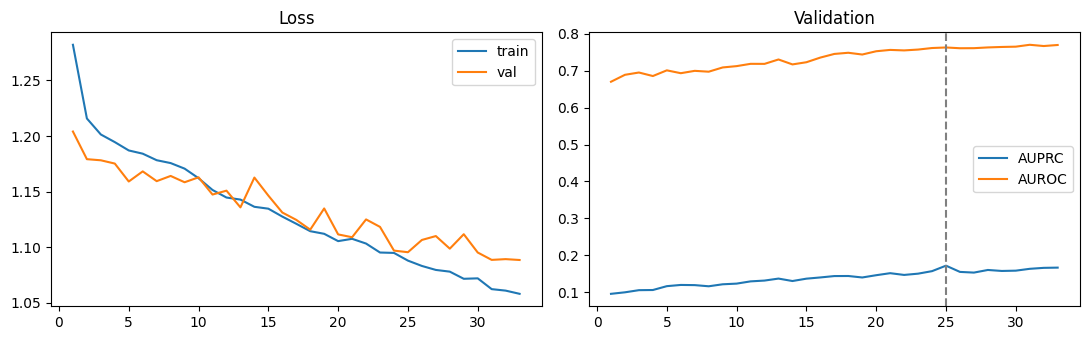

In [26]:
h_shuf1 = pd.DataFrame(hist_shuf1)
print('best epoch:', best_shuf1['epoch'], '| val AUPRC: %.4f' % best_shuf1['auprc'])
model_shuf1.load_state_dict(best_shuf1['state'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_shuf1.epoch, h_shuf1.train_loss, label='train'); ax[0].plot(h_shuf1.epoch, h_shuf1.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h_shuf1.epoch, h_shuf1.val_auprc, label='AUPRC'); ax[1].plot(h_shuf1.epoch, h_shuf1.val_auroc, label='AUROC')
ax[1].axvline(best_shuf1['epoch'], ls='--', c='gray'); ax[1].set_title('Validation'); ax[1].legend()
plt.tight_layout(); plt.show()

### GAT (shuffled seed 1) - Results

In [27]:
va = validate(model_shuf1, edge_index_shuf1, ent_val, y_val, criterion)
thr = best_threshold(y_val.cpu().numpy(), va['probs'])      # threshold picked on validation only
te = validate(model_shuf1, edge_index_shuf1, ent_test, y_test, criterion)
RESULTS['GAT (shuffled seed 1)'] = test_report(y_test.cpu().numpy(), te['probs'], thr)
pd.Series(RESULTS['GAT (shuffled seed 1)']).round(4)

,0
AUPRC,0.1402
AUROC,0.7485
Precision,0.2046
Recall,0.2644
F1,0.2306
Threshold,0.7800


## GAT (shuffled seed 2)

### GAT (shuffled seed 2) - Setup

In [28]:
set_seed(SEED)
edge_index_shuf2 = load_edges(PATHS['shuf2'])
print('edges:', edge_index_shuf2.shape)
model_shuf2 = GAT(NUM_NODES, node_type.to(device), N_TYPES).to(device)
opt_shuf2 = torch.optim.AdamW(model_shuf2.parameters(), lr=LR, weight_decay=WD)
print(sum(p.numel() for p in model_shuf2.parameters()), 'parameters')

edges: torch.Size([2, 563380])
994817 parameters


### GAT (shuffled seed 2) - Train

In [29]:
hist_shuf2 = []
best_shuf2 = {'auprc': -1, 'epoch': 0, 'state': None}
bad = 0
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model_shuf2, edge_index_shuf2, ent_train, y_train, opt_shuf2, criterion)
    va = validate(model_shuf2, edge_index_shuf2, ent_val, y_val, criterion)
    hist_shuf2.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': va['loss'],
                        'val_auprc': va['auprc'], 'val_auroc': va['auroc']})
    print(f"epoch {epoch:02d} | train {tr_loss:.4f} | val {va['loss']:.4f} | "
          f"AUPRC {va['auprc']:.4f} | AUROC {va['auroc']:.4f}")
    if va['auprc'] > best_shuf2['auprc']:
        best_shuf2 = {'auprc': va['auprc'], 'epoch': epoch,
                      'state': {k: v.detach().clone() for k, v in model_shuf2.state_dict().items()}}
        bad = 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop'); break

epoch 01 | train 1.2857 | val 1.1972 | AUPRC 0.0960 | AUROC 0.6749
epoch 02 | train 1.2175 | val 1.1807 | AUPRC 0.1018 | AUROC 0.6946
epoch 03 | train 1.2038 | val 1.1719 | AUPRC 0.1070 | AUROC 0.7005
epoch 04 | train 1.1926 | val 1.1698 | AUPRC 0.1077 | AUROC 0.7015
epoch 05 | train 1.1869 | val 1.1676 | AUPRC 0.1084 | AUROC 0.7049
epoch 06 | train 1.1807 | val 1.1515 | AUPRC 0.1204 | AUROC 0.7151
epoch 07 | train 1.1772 | val 1.1562 | AUPRC 0.1167 | AUROC 0.7087
epoch 08 | train 1.1723 | val 1.1525 | AUPRC 0.1172 | AUROC 0.7134
epoch 09 | train 1.1694 | val 1.1531 | AUPRC 0.1217 | AUROC 0.7169
epoch 10 | train 1.1621 | val 1.1575 | AUPRC 0.1182 | AUROC 0.7068
epoch 11 | train 1.1568 | val 1.1544 | AUPRC 0.1217 | AUROC 0.7126
epoch 12 | train 1.1516 | val 1.1503 | AUPRC 0.1252 | AUROC 0.7163
epoch 13 | train 1.1495 | val 1.1449 | AUPRC 0.1251 | AUROC 0.7212
epoch 14 | train 1.1433 | val 1.1533 | AUPRC 0.1194 | AUROC 0.7181
epoch 15 | train 1.1381 | val 1.1491 | AUPRC 0.1272 | AUROC 0.

### GAT (shuffled seed 2) - Best Epoch

best epoch: 52 | val AUPRC: 0.1829


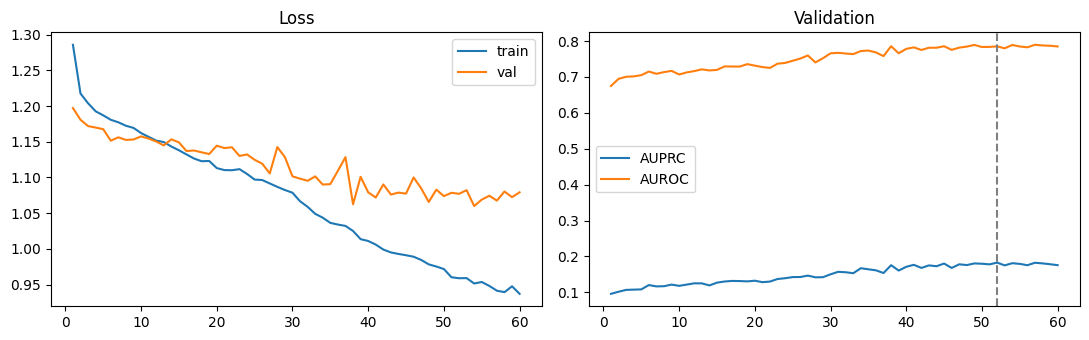

In [30]:
h_shuf2 = pd.DataFrame(hist_shuf2)
print('best epoch:', best_shuf2['epoch'], '| val AUPRC: %.4f' % best_shuf2['auprc'])
model_shuf2.load_state_dict(best_shuf2['state'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_shuf2.epoch, h_shuf2.train_loss, label='train'); ax[0].plot(h_shuf2.epoch, h_shuf2.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h_shuf2.epoch, h_shuf2.val_auprc, label='AUPRC'); ax[1].plot(h_shuf2.epoch, h_shuf2.val_auroc, label='AUROC')
ax[1].axvline(best_shuf2['epoch'], ls='--', c='gray'); ax[1].set_title('Validation'); ax[1].legend()
plt.tight_layout(); plt.show()

### GAT (shuffled seed 2) - Results

In [31]:
va = validate(model_shuf2, edge_index_shuf2, ent_val, y_val, criterion)
thr = best_threshold(y_val.cpu().numpy(), va['probs'])      # threshold picked on validation only
te = validate(model_shuf2, edge_index_shuf2, ent_test, y_test, criterion)
RESULTS['GAT (shuffled seed 2)'] = test_report(y_test.cpu().numpy(), te['probs'], thr)
pd.Series(RESULTS['GAT (shuffled seed 2)']).round(4)

,0
AUPRC,0.1318
AUROC,0.7496
Precision,0.1558
Recall,0.2306
F1,0.1860
Threshold,0.8669


## GAT (shuffled seed 42)

### GAT (shuffled seed 42) - Setup

In [32]:
set_seed(SEED)
edge_index_shuf42 = load_edges(PATHS['shuf42'])
print('edges:', edge_index_shuf42.shape)
model_shuf42 = GAT(NUM_NODES, node_type.to(device), N_TYPES).to(device)
opt_shuf42 = torch.optim.AdamW(model_shuf42.parameters(), lr=LR, weight_decay=WD)
print(sum(p.numel() for p in model_shuf42.parameters()), 'parameters')

edges: torch.Size([2, 563346])
994817 parameters


### GAT (shuffled seed 42) - Train

In [33]:
hist_shuf42 = []
best_shuf42 = {'auprc': -1, 'epoch': 0, 'state': None}
bad = 0
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model_shuf42, edge_index_shuf42, ent_train, y_train, opt_shuf42, criterion)
    va = validate(model_shuf42, edge_index_shuf42, ent_val, y_val, criterion)
    hist_shuf42.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': va['loss'],
                        'val_auprc': va['auprc'], 'val_auroc': va['auroc']})
    print(f"epoch {epoch:02d} | train {tr_loss:.4f} | val {va['loss']:.4f} | "
          f"AUPRC {va['auprc']:.4f} | AUROC {va['auroc']:.4f}")
    if va['auprc'] > best_shuf42['auprc']:
        best_shuf42 = {'auprc': va['auprc'], 'epoch': epoch,
                      'state': {k: v.detach().clone() for k, v in model_shuf42.state_dict().items()}}
        bad = 0
    else:
        bad += 1
        if bad >= PATIENCE:
            print('early stop'); break

epoch 01 | train 1.2856 | val 1.2049 | AUPRC 0.0919 | AUROC 0.6705
epoch 02 | train 1.2157 | val 1.1839 | AUPRC 0.0993 | AUROC 0.6954
epoch 03 | train 1.1989 | val 1.1744 | AUPRC 0.1068 | AUROC 0.7034
epoch 04 | train 1.1902 | val 1.1674 | AUPRC 0.1107 | AUROC 0.6983
epoch 05 | train 1.1836 | val 1.1601 | AUPRC 0.1172 | AUROC 0.7135
epoch 06 | train 1.1805 | val 1.1645 | AUPRC 0.1166 | AUROC 0.7031
epoch 07 | train 1.1753 | val 1.1720 | AUPRC 0.1127 | AUROC 0.6962
epoch 08 | train 1.1723 | val 1.2128 | AUPRC 0.1147 | AUROC 0.6990
epoch 09 | train 1.1708 | val 1.1530 | AUPRC 0.1248 | AUROC 0.7202
epoch 10 | train 1.1628 | val 1.1610 | AUPRC 0.1259 | AUROC 0.7153
epoch 11 | train 1.1552 | val 1.1420 | AUPRC 0.1287 | AUROC 0.7245
epoch 12 | train 1.1575 | val 1.1509 | AUPRC 0.1266 | AUROC 0.7251
epoch 13 | train 1.1510 | val 1.1433 | AUPRC 0.1267 | AUROC 0.7297
epoch 14 | train 1.1418 | val 1.1578 | AUPRC 0.1235 | AUROC 0.7310
epoch 15 | train 1.1406 | val 1.1418 | AUPRC 0.1342 | AUROC 0.

### GAT (shuffled seed 42) - Best Epoch

best epoch: 47 | val AUPRC: 0.1805


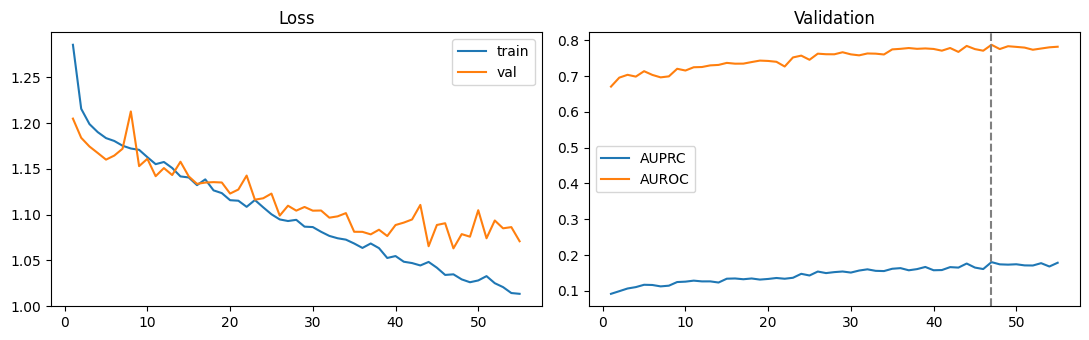

In [34]:
h_shuf42 = pd.DataFrame(hist_shuf42)
print('best epoch:', best_shuf42['epoch'], '| val AUPRC: %.4f' % best_shuf42['auprc'])
model_shuf42.load_state_dict(best_shuf42['state'])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_shuf42.epoch, h_shuf42.train_loss, label='train'); ax[0].plot(h_shuf42.epoch, h_shuf42.val_loss, label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h_shuf42.epoch, h_shuf42.val_auprc, label='AUPRC'); ax[1].plot(h_shuf42.epoch, h_shuf42.val_auroc, label='AUROC')
ax[1].axvline(best_shuf42['epoch'], ls='--', c='gray'); ax[1].set_title('Validation'); ax[1].legend()
plt.tight_layout(); plt.show()

### GAT (shuffled seed 42) - Results

In [35]:
va = validate(model_shuf42, edge_index_shuf42, ent_val, y_val, criterion)
thr = best_threshold(y_val.cpu().numpy(), va['probs'])      # threshold picked on validation only
te = validate(model_shuf42, edge_index_shuf42, ent_test, y_test, criterion)
RESULTS['GAT (shuffled seed 42)'] = test_report(y_test.cpu().numpy(), te['probs'], thr)
pd.Series(RESULTS['GAT (shuffled seed 42)']).round(4)

,0
AUPRC,0.1327
AUROC,0.7473
Precision,0.1739
Recall,0.3331
F1,0.2286
Threshold,0.7287


## 5. Comparison

In [36]:
res = pd.DataFrame(RESULTS).T.round(4)
res

,AUPRC,AUROC,Precision,Recall,F1,Threshold
GAT (real graph),0.1599,0.7714,0.2693,0.2543,0.2616,0.8293
GAT (shuffled seed 1),0.1402,0.7485,0.2046,0.2644,0.2306,0.7800
GAT (shuffled seed 2),0.1318,0.7496,0.1558,0.2306,0.1860,0.8669
GAT (shuffled seed 42),0.1327,0.7473,0.1739,0.3331,0.2286,0.7287


In [37]:
shuf = res[res.index.str.contains('shuffled')]
real = res.loc['GAT (real graph)']
print('Shuffled mean AUPRC: %.4f +- %.4f' % (shuf.AUPRC.mean(), shuf.AUPRC.std()))
print('Real graph AUPRC:    %.4f' % real.AUPRC)
print('Gain from real structure: %+.4f AUPRC' % (real.AUPRC - shuf.AUPRC.mean()))

Shuffled mean AUPRC: 0.1349 +- 0.0046
Real graph AUPRC:    0.1599
Gain from real structure: +0.0250 AUPRC


## 6. Save results to CSV

In [38]:
import os
OUT_DIR = '/content/drive/MyDrive/fraud_project/results'
os.makedirs(OUT_DIR, exist_ok=True)

res = pd.DataFrame(RESULTS).T.round(4)
res.index.name = 'model'
res.to_csv(f'{OUT_DIR}/gat_results.csv')
print('saved', f'{OUT_DIR}/gat_results.csv')
res

saved /content/drive/MyDrive/fraud_project/results/gat_results.csv


,AUPRC,AUROC,Precision,Recall,F1,Threshold
model,,,,,,
GAT (real graph),0.1599,0.7714,0.2693,0.2543,0.2616,0.8293
GAT (shuffled seed 1),0.1402,0.7485,0.2046,0.2644,0.2306,0.7800
GAT (shuffled seed 2),0.1318,0.7496,0.1558,0.2306,0.1860,0.8669
GAT (shuffled seed 42),0.1327,0.7473,0.1739,0.3331,0.2286,0.7287


In [39]:
# per-epoch training curves for every run, in one long-format CSV
hists = []
for name, h in [('GAT (real graph)', h_real), ('GAT (shuffled seed 1)', h_shuf1),
                ('GAT (shuffled seed 2)', h_shuf2), ('GAT (shuffled seed 42)', h_shuf42)]:
    hists.append(h.assign(model=name))
pd.concat(hists).to_csv(f'{OUT_DIR}/gat_training_history.csv', index=False)
print('saved', f'{OUT_DIR}/gat_training_history.csv')

saved /content/drive/MyDrive/fraud_project/results/gat_training_history.csv
